# plot_HS_countries — regional GeoMIP surface-temperature response

Python port of `plot_HS_countries.m`. Loads the GeoMIP multi-model `tas`
ensemble, computes global and IPCC-region mean temperature responses
(G6sulfur and G6solar, each relative to SSP2-4.5), and the end-of-century
multi-model variances, which are saved to a `.mat` file.

This is a close cousin of `plot_HS_GeoMIP`, differing in that it (a) loads the
unused `borderdata.mat`, (b) carries only the two SRM experiments
(G6sulfur, G6solar), and (c) uses `mean(...,'omitnan')` in the zonal mean.

The analysis is a faithful 1:1 translation of the MATLAB script; only the
plotting back-end (matplotlib) and the colour/utility helpers (`mat_utils`)
differ.

In [1]:
import sys
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import mat_utils as mu
from mat_utils import brewermap, brighten, movmean, ncread, shaperead, inpolygon, interp1, interp2

## Load data
`GeoMIP_tas.mat` holds the cell array `x_e{model, experiment, member}` of
`tas` fields (lon × lat × year) plus the per-model `LAT`/`LON` cells.
`borderdata.mat` is loaded by the MATLAB script for fidelity but is **not**
used in any computation.

In [2]:
m = mu.load_npz("GeoMIP_tas")     # data_py/GeoMIP_tas.npz (regenerated from raw; see read_GeoMIP_models)
x_e = m["x_e"]          # object array, shape (6, 4, 3)
LAT = m["LAT"]          # object array, shape (1, 6)
LON = m["LON"]          # object array, shape (1, 6)

borderdata = mu.loadmat("borderdata.mat")   # loaded for fidelity; unused

## Global means
For each model/experiment/member, take the (NaN-omitting) zonal mean over
longitude and the cosine-latitude weighted mean over latitude. Models whose
record starts in 2015 (86 years) are trimmed to 2020–2100 (`y(6:86)` in
MATLAB → `y[5:86]`). The MATLAB inner loop runs `in=1:3`.

In [3]:
x_e_gm = np.full((6, 4, 3, 81), np.nan)

for im in range(6):
    lat = LAT[0, im].ravel()
    ww = np.cos(lat / 180 * np.pi)
    for ie in range(4):
        for inn in range(3):                        # MATLAB: for in=1:3
            field = x_e[im, ie, inn]
            if np.size(field) > 0 and field.shape[0] > 0:
                zm = np.nanmean(field, axis=0)      # mean over lon (omitnan)
                y = np.sum(zm * ww[:, None], axis=0) / np.sum(ww)
                if y.shape[0] == 86:
                    x_e_gm[im, ie, inn, 0:81] = y[5:86]
                else:
                    x_e_gm[im, ie, inn, :] = y

## Regional means
Regions come from the IPCC-WGI reference regions shapefile. For each model the
area-weighted regional mean of the (experiment − SSP2-4.5) difference is
accumulated for every year and **every** region. Only the two SRM experiments
are carried (G6sulfur, G6solar).

In [4]:
regions = shaperead("IPCC-WGI-reference-regions-v4.shx")
nR = len(regions)

ta_reg_sulf = np.full((6, 81, nR), np.nan)
ta_reg_solar = np.full((6, 81, nR), np.nan)

for im in range(6):
    lat = LAT[0, im].ravel()
    lon = LON[0, im].ravel()
    ww = np.cos(lat / 180 * np.pi)

    # MATLAB meshgrid(LAT,LON-180) and meshgrid(ww,LON) -> arrays (nlon, nlat)
    latM, lonM = np.meshgrid(lat, lon - 180)       # both (nlon, nlat)
    AA = np.meshgrid(ww, lon)[0]                    # (nlon, nlat), AA[i,j]=ww[j]

    ta_1 = (x_e[im, 0, 0][:, :, 0:81] - x_e[im, 3, 0][:, :, 0:81]) * AA[:, :, None]
    ta_2 = (x_e[im, 1, 0][:, :, 0:81] - x_e[im, 3, 0][:, :, 0:81]) * AA[:, :, None]

    for i in range(nR):
        print(regions[i].Name)
        ind = inpolygon(latM, lonM, regions[i].Y, regions[i].X)
        wS = np.sum(AA[ind])
        for j in range(81):
            ta_reg_sulf[im, j, i] = np.nansum(ta_1[:, :, j][ind]) / wS
            ta_reg_solar[im, j, i] = np.nansum(ta_2[:, :, j][ind]) / wS

Greenland/Iceland
N.W.North-America
N.E.North-America
W.North-America
C.North-America
E.North-America
N.Central-America
S.Central-America
Caribbean
N.W.South-America
N.South-America
N.E.South-America


South-American-Monsoon
S.W.South-America
S.E.South-America
S.South-America
N.Europe
West&Central-Europe
E.Europe
Mediterranean
Sahara
Western-Africa
Central-Africa
N.Eastern-Africa
S.Eastern-Africa


W.Southern-Africa
E.Southern-Africa
Madagascar
Russian-Arctic
W.Siberia
E.Siberia
Russian-Far-East
W.C.Asia
E.C.Asia
Tibetan-Plateau


E.Asia
Arabian-Peninsula
S.Asia
S.E.Asia
N.Australia
C.Australia
E.Australia
S.Australia
New-Zealand
E.Antarctica


W.Antarctica
Arctic-Ocean
N.Pacific-Ocean


...

W.Antarctica
Arctic-Ocean


N.Pacific-Ocean
Equatorial.Pacific-Ocean


S.Pacific-Ocean
N.Atlantic-Ocean


Equatorial.Atlantic-Ocean
S.Atlantic-Ocean
Arabian-Sea
Bay-of-Bengal
Equatorial.Indian-Ocean


S.Indian-Ocean
Southern-Ocean


## Plot the first region
The MATLAB script does no plotting. To embed a figure (and to make the
computed series visible) we reproduce the per-region time-series plot for the
first IPCC-WGI region, following the style of `plot_HS_GeoMIP`: per-model thin
lines plus the multi-model mean (thick), each smoothed with a 10-year moving
mean. Black = G6sulfur, blue = G6solar.

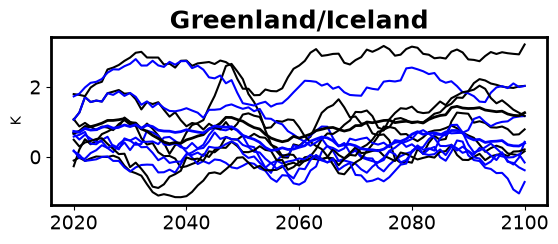

In [5]:
i = 0                       # MATLAB region index 1
time = np.arange(2020, 2101)
mvm = 10

fig = plt.figure()
ax = fig.add_subplot(2, 1, 1)
for im in range(6):
    ax.plot(time, movmean(ta_reg_sulf[im, :, i], mvm), "k")
    ax.plot(time, movmean(ta_reg_solar[im, :, i], mvm), "b")

ax.plot(time, movmean(np.nanmean(ta_reg_sulf[:, :, i], axis=0), mvm), "k", linewidth=2)
ax.plot(time, movmean(np.nanmean(ta_reg_solar[:, :, i], axis=0), mvm), "b", linewidth=2)

ax.set_title(regions[i].Name, fontsize=18, fontweight="bold", color="k")
ax.set_ylabel("K")
for s in ax.spines.values():
    s.set_linewidth(2)
ax.tick_params(labelsize=14)
fig.set_facecolor("w")
ax.set_facecolor("w")
plt.show()

## End-of-century variances
Multi-model variance of the 2080–2100 mean response (years 61:81 in MATLAB →
`[60:81]`), with the 2080–2100 mean taken NaN-omitting (`mean(...,'omitnan')`)
and the sample standard deviation (`std(...,0)` → `ddof=1`).

In [6]:
ta_var_sulf = np.full(nR, np.nan)
ta_var_solar = np.full(nR, np.nan)

for i in range(nR):
    x = np.nanmean(ta_reg_sulf[:, 60:81, i], axis=1)
    y = np.nanmean(ta_reg_solar[:, 60:81, i], axis=1)
    ta_var_sulf[i] = np.std(x, ddof=1) ** 2
    ta_var_solar[i] = np.std(y, ddof=1) ** 2

print("region 0 variances (sulf, solar):",
      ta_var_sulf[0], ta_var_solar[0])

region 0 variances (sulf, solar): 0.989617706799384 0.65870422209319


## Save outputs
The MATLAB script ends with `save('tas_regions1_std.mat', ...)` writing only
two variables (`ta_var_sulf`, `ta_var_solar`). In the original MATLAB this
**collides** with the 3-variable `tas_regions1_std.mat` produced by
`plot_HS_GeoMIP` (which the downstream scatter scripts depend on). To preserve
this script's distinct output without breaking that pipeline, we write it
under a distinct Python-native name, `data_py/tas_regions1_std_countries.npz`.

In [7]:
mu.save_npz("tas_regions1_std_countries",
            ta_var_sulf=ta_var_sulf,
            ta_var_solar=ta_var_solar)
print("saved data_py/tas_regions1_std_countries.npz")

saved data_py/tas_regions1_std_countries.npz
